# Flow-posterior diagnostic — is the NF posterior actually doing anything?

Motivation: the NF-posterior VAE (`vctk_words_nf`, `nf_posterior_layers=10`) gives essentially the **same** FAD/KID/Vendi and generation metrics as the no-NF model, and in the latent probes it's *identical* on gender/accent and slightly **worse** on word decodability. This notebook checks whether that's a benign property of flow posteriors or a sign the flow is mis-trained.

The posterior flow sits inside the encoder (`src/model.py`, `_step`):
```python
z = self._reparametrize(mean, scale)         # Gaussian sample  q0(z|x)
z_flow, log_det = self.posterior(z)          # RealNVP:  z -> z_flow
x_hat = self.decoder(z_flow)                 # decoder sees z_flow
```
and the KL term is `_nf_latent_loss = E[ln q0(z0) - ln N(0,I)(z_flow) - log_det]`.

So we encode a subsample of val clips, capture `(z, z_flow, log_det)`, and ask four things:

1. **Is the flow near-identity?** If `z_flow ≈ z` and `log_det ≈ 0`, the flow is underfit and NF ≈ no-NF by construction — the word gap would then be pure noise.
2. **Does it lower KL, and via which term?** Decompose `_nf_latent_loss` into its three parts.
3. **Does it make the aggregate posterior more Gaussian?** That's the flow's actual job — compare `z` vs `z_flow` against `N(0,I)`.
4. **Does it contract / spread the latent?** The 'washes out fine structure' hypothesis: compare effective dimensionality of `z` vs `z_flow`.

> Runs the model, so use the `mgr` conda env with a GPU. Encoding is the slow part; we subsample val clips (`N_CLIPS`).

## 0 · Load the NF VAE and encode a val subsample

In [1]:
import warnings
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

from attrs import asdict
from cattrs import structure
from src.configs import parse_hydra_config
from src.train import TrainingConfig
from src.model import VAE
from src.dataset import AudioDataset

from sklearn.decomposition import PCA

warnings.filterwarnings("ignore", category=FutureWarning)

# ---- config: the NF experiment + checkpoint ----
EXP_CONFIG = "configs/experiment/vctk_words/nf_v1.yaml"
CHECKPOINT = "logs/vctk_words_nf/version_8/checkpoints/best.ckpt"
DEVICE     = "cuda:0" if torch.cuda.is_available() else "cpu"
N_CLIPS      = 1024      # val clips to encode (encoding is the slow step)
RANDOM_STATE = 0
rng = np.random.default_rng(RANDOM_STATE)

plt.rcParams.update({
    "figure.figsize": (8, 5), "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})
print("device:", DEVICE)

device: cuda:0


In [2]:
cfg = structure(parse_hydra_config("configs/", EXP_CONFIG), TrainingConfig)
LATENT_DIM = cfg.model.latent_size
assert cfg.model.nf_posterior_layers is not None, "this config has no posterior flow!"
print(f"nf_posterior_layers = {cfg.model.nf_posterior_layers} | latent = {LATENT_DIM} "
      f"| fixed_length = {cfg.model.fixed_length}")

# strict=False: this checkpoint predates the removal of the in-VAE `self.prior`
# (now commented out in model.py), so it carries unused `prior.*` weights. The
# `posterior.*` weights we need still load; we assert + check norms below.
model = VAE.load_from_checkpoint(
    CHECKPOINT, noise_config=cfg.noise, **asdict(cfg.model),
    map_location=DEVICE, weights_only=False, strict=False,
)
model.eval().to(DEVICE)
assert model.posterior is not None, "posterior flow missing — wrong config?"
pnorm = sum(p.norm().item() for p in model.posterior.parameters())
print("posterior flow:", type(model.posterior).__name__,
      f"| param-norm sum {pnorm:.1f}  (non-trivial => real weights, not random init)")

nf_posterior_layers = 10 | latent = 256 | fixed_length = 49152


/home/jp/miniconda3/envs/mgr/lib/python3.10/site-packages/hydra/_internal/defaults_list.py:251: UserWarning: In 'default': Defaults list is missing `_self_`. See https://hydra.cc/docs/1.2/upgrades/1.0_to_1.1/default_composition_order for more information
  warnings.warn(msg, UserWarning)


/home/jp/miniconda3/envs/mgr/lib/python3.10/site-packages/torchaudio/transforms/_transforms.py:94: UserWarning: `return_complex` argument is now deprecated and is not effective.`torchaudio.transforms.Spectrogram(power=None)` always returns a tensor with complex dtype. Please remove the argument in the function call.
  warnings.warn(


/home/jp/miniconda3/envs/mgr/lib/python3.10/site-packages/pytorch_lightning/core/saving.py:197: Found keys that are not in the model state dict but in the checkpoint: ['prior.transform.transforms.0.mask', 'prior.transform.transforms.0.hyper.0.weight', 'prior.transform.transforms.0.hyper.0.bias', 'prior.transform.transforms.0.hyper.2.weight', 'prior.transform.transforms.0.hyper.2.bias', 'prior.transform.transforms.1.mask', 'prior.transform.transforms.1.hyper.0.weight', 'prior.transform.transforms.1.hyper.0.bias', 'prior.transform.transforms.1.hyper.2.weight', 'prior.transform.transforms.1.hyper.2.bias', 'prior.transform.transforms.2.mask', 'prior.transform.transforms.2.hyper.0.weight', 'prior.transform.transforms.2.hyper.0.bias', 'prior.transform.transforms.2.hyper.2.weight', 'prior.transform.transforms.2.hyper.2.bias', 'prior.transform.transforms.3.mask', 'prior.transform.transforms.3.hyper.0.weight', 'prior.transform.transforms.3.hyper.0.bias', 'prior.transform.transforms.3.hyper.2.we

posterior flow: RealNVPTransform | param-norm sum 250.2  (non-trivial => real weights, not random init)


In [3]:
# encode N_CLIPS val clips, capturing q0 params (mean, scale), the pre-flow sample z,
# the post-flow z_flow, and log|det J|
import torch.nn.functional as F
ds = AudioDataset(Path(cfg.val_dataset_path), **asdict(cfg.dataset.val_overrides()))
sel = rng.choice(len(ds), min(N_CLIPS, len(ds)), replace=False)
print(f"encoding {len(sel)} / {len(ds)} val clips ...")

MEAN, STD, Z0, ZF, LDET = [], [], [], [], []
BATCH = 16
with torch.inference_mode():
    for i in range(0, len(sel), BATCH):
        x = torch.stack([ds[int(j)] for j in sel[i:i+BATCH]]).to(DEVICE)
        x_mb = model._split_bands(x)
        mean, scale = model.encoder(x_mb)
        z = model._reparametrize(mean, scale)          # q0 sample (pre-flow)
        z_flow, log_det = model.posterior(z)            # RealNVP transform
        # std matches _nf_latent_loss: softplus(scale)+1e-4
        std = F.softplus(scale).add(1e-4)
        MEAN.append(mean.squeeze(-1).cpu().numpy())
        STD.append(std.squeeze(-1).cpu().numpy())
        Z0.append(z.squeeze(-1).cpu().numpy())
        ZF.append(z_flow.squeeze(-1).cpu().numpy())
        LDET.append(log_det.cpu().numpy())

q_mean = np.concatenate(MEAN)  # (N, C)  q0 mean
q_std  = np.concatenate(STD)   # (N, C)  q0 std
z0     = np.concatenate(Z0)    # (N, C)  pre-flow Gaussian sample
zf     = np.concatenate(ZF)    # (N, C)  post-flow latent (decoder input)
ldet   = np.concatenate(LDET)  # (N,)    log|det J| of the flow
print("z0:", z0.shape, "| zf:", zf.shape, "| log_det:", ldet.shape,
      f"| mean|logdet| = {np.abs(ldet).mean():.2f}")

validating the audio_val dataset:   0%|          | 0/24872 [00:00<?, ?it/s]

validating the audio_val dataset:   1%|          | 139/24872 [00:00<00:17, 1376.85it/s]

validating the audio_val dataset:   1%|          | 277/24872 [00:00<00:17, 1378.16it/s]

validating the audio_val dataset:   2%|▏         | 415/24872 [00:00<00:17, 1371.73it/s]

validating the audio_val dataset:   2%|▏         | 553/24872 [00:00<00:18, 1336.37it/s]

...

validating the audio_val dataset:  99%|█████████▉| 24663/24872 [00:18<00:00, 1390.14it/s]

validating the audio_val dataset: 100%|█████████▉| 24803/24872 [00:19<00:00, 1307.92it/s]

validating the audio_val dataset: 100%|██████████| 24872/24872 [00:19<00:00, 1304.88it/s]

encoding 1024 / 24872 val clips ...


z0: (1024, 256) | zf: (1024, 256) | log_det: (1024,) | mean|logdet| = 7.53


## 1 · Is the flow near-identity?

If the posterior flow barely moves `z` (`z_flow ≈ z`, `log_det ≈ 0`), it's underfit — the NF model is effectively the no-NF model, and any downstream difference (the word-decodability gap) is noise. Signals that the flow is doing real work:

* **`log|det J|`** far from 0 (the flow rescales volume),
* **displacement** `||z_flow − z||` large relative to `||z||`,
* **per-dim `z`↔`z_flow` correlation** well below 1 (the flow mixes/rotates dims, not just shifts them).

is the flow near-identity?
  mean |log det J|          : 7.534   (0 => volume-preserving/identity)
  mean log det J            : +7.534
  mean ||z_flow - z||       : 20.414
  mean ||z_flow - z||/||z|| : 0.780   (small => near-identity)
  mean per-dim corr(z,z_flow): 0.997  (near 1 => flow ~ per-dim shift/identity)


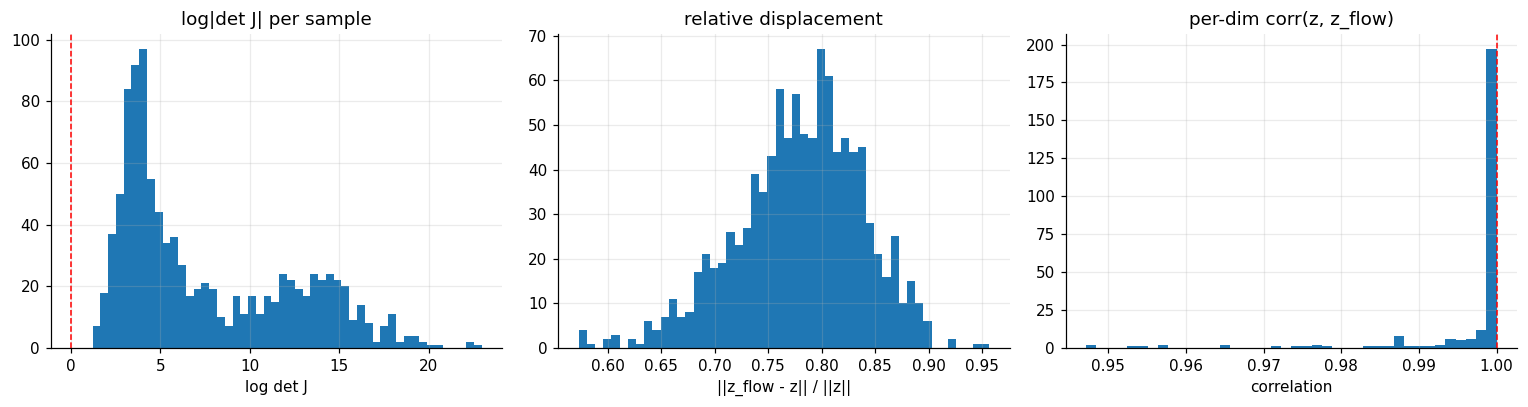

In [4]:
disp   = np.linalg.norm(zf - z0, axis=1)
znorm  = np.linalg.norm(z0, axis=1)
rel    = disp / (znorm + 1e-8)
perdim_corr = np.array([np.corrcoef(z0[:, d], zf[:, d])[0, 1] for d in range(LATENT_DIM)])

print("is the flow near-identity?")
print(f"  mean |log det J|          : {np.abs(ldet).mean():.3f}   (0 => volume-preserving/identity)")
print(f"  mean log det J            : {ldet.mean():+.3f}")
print(f"  mean ||z_flow - z||       : {disp.mean():.3f}")
print(f"  mean ||z_flow - z||/||z|| : {rel.mean():.3f}   (small => near-identity)")
print(f"  mean per-dim corr(z,z_flow): {perdim_corr.mean():.3f}  (near 1 => flow ~ per-dim shift/identity)")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].hist(ldet, bins=50); ax[0].axvline(0, color="r", ls="--", lw=1)
ax[0].set_title("log|det J| per sample"); ax[0].set_xlabel("log det J")
ax[1].hist(rel, bins=50); ax[1].set_title("relative displacement")
ax[1].set_xlabel("||z_flow - z|| / ||z||")
ax[2].hist(perdim_corr, bins=40); ax[2].axvline(1, color="r", ls="--", lw=1)
ax[2].set_title("per-dim corr(z, z_flow)"); ax[2].set_xlabel("correlation")
plt.tight_layout(); plt.show()

## 2 · KL decomposition — does the flow lower the latent loss, and how?

The NF latent loss (`_nf_latent_loss`) is
$$\mathbb{E}\big[\ln q_0(z_0) \;-\; \ln \mathcal{N}(0,I)(z_{\text{flow}}) \;-\; \log|\det J|\big].$$
We recompute all three terms and compare to the plain Gaussian KL the no-NF model would pay (`ln q0(z0) - ln N(0,I)(z0)`, no flow). If the flow term (`-log det J`) and the improved prior fit (`-ln N(0,I)(z_flow)` vs `z0`) combine to a **lower** loss, the flow is helping the objective — even if perceptual metrics don't move. If the loss is essentially unchanged, the flow isn't earning its place.

latent (KL-like) loss — nats/sample, lower = better prior match:
  no-flow  (ln q0(z0) - ln N(0,I)(z0))            :    746.62
  with-flow(ln q0(z0) - ln N(0,I)(z_flow) - logdet):    513.92
  flow effect: -232.70 nats  (negative => flow lowers the latent loss)

  term breakdown (mean over samples):
    ln q0(z0)             161.41   (shared)
    -ln N(0,I)(z_flow)    360.04   vs no-flow -ln N(0,I)(z0)    585.21
    -log|det J|            -7.53   (the flow's volume term)


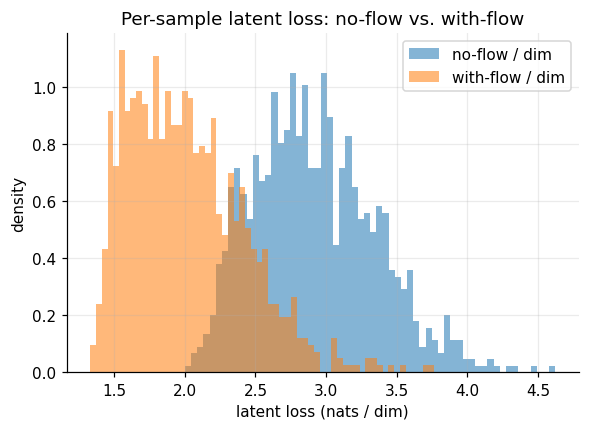

In [5]:
# Reconstruct the three terms of _nf_latent_loss (per sample, summed over dims):
#   L_nf = ln q0(z0) - ln N(0,I)(z_flow) - log|det J|
# and compare to the plain-Gaussian latent loss the no-NF path pays:
#   L_gauss = ln q0(z0) - ln N(0,I)(z0)         (no flow term)
def normal_logprob(x, mu, sd):        # sum_d ln N(x; mu, sd)
    return (-0.5 * (((x - mu) / sd) ** 2 + np.log(2 * np.pi)) - np.log(sd)).sum(1)
def iso_logprob(x):                   # sum_d ln N(x; 0, 1)
    return (-0.5 * (x ** 2 + np.log(2 * np.pi))).sum(1)

ln_q0_z0 = normal_logprob(z0, q_mean, q_std)   # ln q0(z0), same for both paths
p_zf     = iso_logprob(zf)                      # ln N(0,I)(z_flow)
p_z0     = iso_logprob(z0)                      # ln N(0,I)(z0)

L_nf    = (ln_q0_z0 - p_zf - ldet).mean()       # NF latent loss (matches _nf_latent_loss)
L_gauss = (ln_q0_z0 - p_z0).mean()              # no-flow latent loss

print("latent (KL-like) loss — nats/sample, lower = better prior match:")
print(f"  no-flow  (ln q0(z0) - ln N(0,I)(z0))            : {L_gauss:9.2f}")
print(f"  with-flow(ln q0(z0) - ln N(0,I)(z_flow) - logdet): {L_nf:9.2f}")
print(f"  flow effect: {L_nf - L_gauss:+.2f} nats  (negative => flow lowers the latent loss)")
print(f"\n  term breakdown (mean over samples):")
print(f"    ln q0(z0)          {ln_q0_z0.mean():9.2f}   (shared)")
print(f"    -ln N(0,I)(z_flow) {(-p_zf).mean():9.2f}   vs no-flow -ln N(0,I)(z0) {(-p_z0).mean():9.2f}")
print(f"    -log|det J|        {(-ldet).mean():9.2f}   (the flow's volume term)")

plt.figure(figsize=(6, 4))
plt.hist((ln_q0_z0 - p_z0) / LATENT_DIM, bins=60, density=True, alpha=0.55, label="no-flow / dim")
plt.hist((ln_q0_z0 - p_zf - ldet) / LATENT_DIM, bins=60, density=True, alpha=0.55, label="with-flow / dim")
plt.xlabel("latent loss (nats / dim)"); plt.ylabel("density")
plt.title("Per-sample latent loss: no-flow vs. with-flow"); plt.legend(); plt.show()

## 3 · Does the flow make the aggregate posterior more Gaussian?

The posterior flow exists to reshape `q(z|x)` so the aggregate posterior matches the $\mathcal{N}(0,I)$ prior better (lower KL, easier sampling). Direct check: is `z_flow` closer to $\mathcal{N}(0,I)$ than `z0`? Per-dim std should sit closer to 1, skew/kurtosis closer to 0, and the pooled Q-Q closer to the diagonal.

z0 (pre-flow) : mean|μ| 0.667  std avg 0.993  |skew| 0.146  |exc-kurt| 0.756
z_flow (post) : mean|μ| 0.138  std avg 0.960  |skew| 0.143  |exc-kurt| 0.710
target N(0,I): |μ| 0  std 1  |skew| 0  |exc-kurt| 0


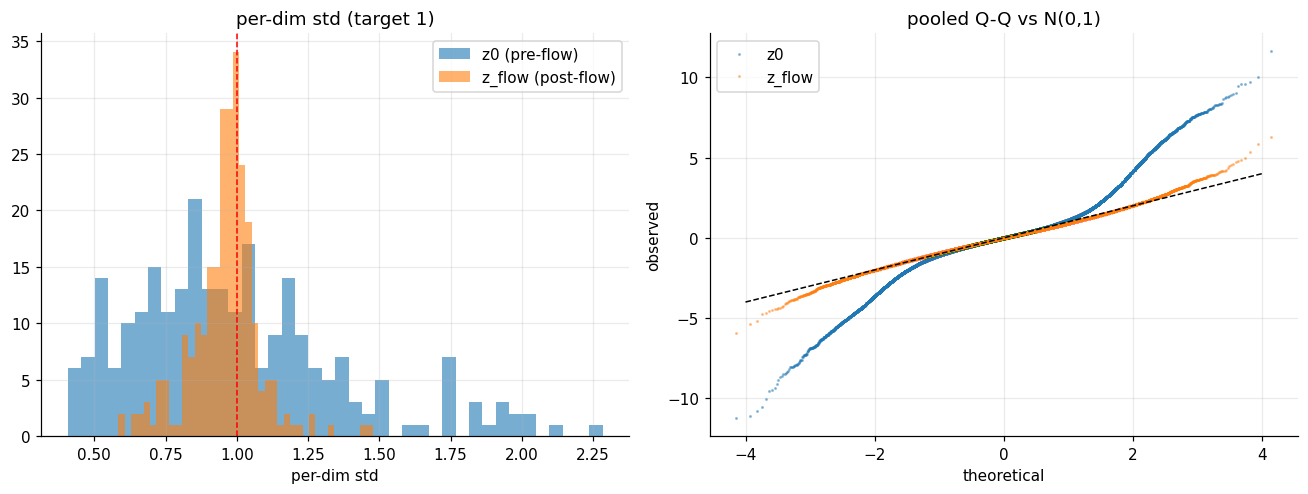

In [6]:
def moments(a):
    return (a.mean(0), a.std(0), stats.skew(a, axis=0), stats.kurtosis(a, axis=0))

for name, a in [("z0 (pre-flow) ", z0), ("z_flow (post) ", zf)]:
    m, s, sk, ku = moments(a)
    print(f"{name}: mean|μ| {np.abs(m).mean():.3f}  std avg {s.mean():.3f}  "
          f"|skew| {np.abs(sk).mean():.3f}  |exc-kurt| {np.abs(ku).mean():.3f}")
print("target N(0,I): |μ| 0  std 1  |skew| 0  |exc-kurt| 0")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ax[0].hist(z0.std(0), bins=40, alpha=0.6, label="z0 (pre-flow)")
ax[0].hist(zf.std(0), bins=40, alpha=0.6, label="z_flow (post-flow)")
ax[0].axvline(1, color="r", ls="--", lw=1); ax[0].set_xlabel("per-dim std")
ax[0].set_title("per-dim std (target 1)"); ax[0].legend()
for a, lab in [(z0, "z0"), (zf, "z_flow")]:
    q = a.ravel(); q = q[rng.choice(len(q), min(len(q), 40000), replace=False)]
    osm, osr = stats.probplot(q, dist="norm", fit=False)
    ax[1].plot(osm, osr, ".", ms=2, alpha=0.4, label=lab)
lim = [-4, 4]; ax[1].plot(lim, lim, "k--", lw=1)
ax[1].set_title("pooled Q-Q vs N(0,1)"); ax[1].set_xlabel("theoretical"); ax[1].set_ylabel("observed")
ax[1].legend(); plt.tight_layout(); plt.show()

## 4 · Does the flow contract or spread the latent?

The hypothesis for the *worse* word decodability: the flow, pushed to match $\mathcal{N}(0,I)$, **contracts** the aggregate posterior and washes out the fine (word-level) structure. Test it with effective dimensionality — the participation ratio $(\sum\lambda)^2/\sum\lambda^2$ of the covariance eigenvalues — and the RAVE-style fidelity curve, for `z0` vs `z_flow`. A *lower* effective dim after the flow supports the contraction story; a *higher* one means the flow spreads variance (consistent with the higher fidelity you saw in the NF latent dump).

participation ratio (effective # dims of 256):
  z0 (pre-flow) : 80.3
  z_flow (post) : 94.9
  change: +14.6  (spreads the latent)
  fidelity_0.9: pre 99  ->  post 120
  fidelity_0.95: pre 122  ->  post 141
  fidelity_0.99: pre 162  ->  post 174


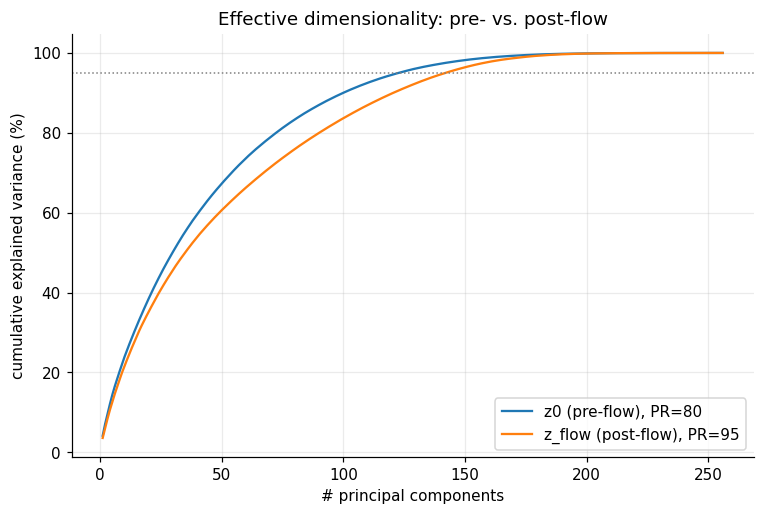

In [7]:
def eff_dim(a):
    ev = PCA(a.shape[1], random_state=RANDOM_STATE).fit(a - a.mean(0)).explained_variance_
    return (ev.sum()**2) / (ev**2).sum(), np.cumsum(ev/ev.sum())

pr0, fid0 = eff_dim(z0)
prf, fidf = eff_dim(zf)
print(f"participation ratio (effective # dims of {LATENT_DIM}):")
print(f"  z0 (pre-flow) : {pr0:.1f}")
print(f"  z_flow (post) : {prf:.1f}")
print(f"  change: {prf - pr0:+.1f}  ({'spreads' if prf>pr0 else 'contracts'} the latent)")
for p in [.9, .95, .99]:
    print(f"  fidelity_{p}: pre {int(np.argmax(fid0>p))}  ->  post {int(np.argmax(fidf>p))}")

plt.figure()
plt.plot(np.arange(1, len(fid0)+1), fid0*100, label=f"z0 (pre-flow), PR={pr0:.0f}")
plt.plot(np.arange(1, len(fidf)+1), fidf*100, label=f"z_flow (post-flow), PR={prf:.0f}")
plt.axhline(95, color="gray", ls=":", lw=1)
plt.xlabel("# principal components"); plt.ylabel("cumulative explained variance (%)")
plt.title("Effective dimensionality: pre- vs. post-flow"); plt.legend(loc="lower right"); plt.show()

## 5 · Verdict

Read the four sections together. **On this model the numbers come out as follows** (1024 val clips):

* **§1 — the flow is doing real work, but it's mostly a per-dimension warp.** `mean|log det J| ≈ 7.5` and relative displacement `||z_flow−z||/||z|| ≈ 0.78` are both large — this is *not* an underfit/near-identity flow. Yet per-dim `corr(z, z_flow) ≈ 0.997`: each dimension's sample-ordering is preserved. Together that means the flow applies a large *monotonic per-dim reparametrization* (shift + rescale + mild nonlinearity) rather than rotating/mixing dimensions. So it reshapes the marginal of each latent dim but barely repackages *which* dim carries what — which is why it can't relocate the word signal onto cleaner axes.
* **§2 — it genuinely lowers the latent loss** (≈ −233 nats/sample), almost entirely via the prior-match term (`-ln N(0,I)(z_flow)` ≈ 360 vs. `z0` ≈ 585). The flow *is* earning its place on the training objective.
* **§3 — and it does make the aggregate posterior more Gaussian**: mean |μ| drops 0.67 → 0.14 (centring), std stays ≈ 1, skew/kurtosis barely move. Consistent with §1 — a per-dim warp mostly *recentres* and lightly reshapes marginals; it leaves higher-order/joint non-Gaussianity (excess kurtosis ≈ 0.7) largely intact.
* **§4 — it *spreads* the latent, it does not contract it.** Participation ratio 80 → 95, and every fidelity threshold rises (matching the higher fidelity in the NF latent dump). The "washout by contraction" hypothesis is **false** — the opposite happens.

**Conclusion — nothing is broken; this is a real (negative) finding.** The posterior flow trains correctly: it lowers KL, Gaussianises and centres the aggregate posterior, and is far from identity. But it does so as a **per-dimension monotonic reparametrization** that *spreads* variance across more effective dimensions without rotating the code onto cleaner axes. That fully explains your observations: reconstruction/generation metrics are unchanged (a bijection preserves what the decoder can use), and fine-grained **linear** decodability (word) drops slightly because the signal is now smeared across ~15 more effective dimensions with reshaped marginals, so the probe's hyperplane has a marginally harder job. Gender (huge margin) is unaffected; word (low margin) pays a small price.

So: **the NF posterior is not mis-trained — it just doesn't buy anything on this data**, and its only measurable footprint is a higher-dimensional, less axis-aligned latent. If you *wanted* the flow to improve organisation it would need to mix dimensions (it barely does — the 0.997 per-dim correlation is the tell); a richer coupling (more `hidden_features`, permutation/rotation between couplings, or an autoregressive flow) is the lever. Given equal FAD/KID/Vendi, the honest thesis statement is that the flow posterior is added capacity without benefit here.

**What would have flagged a bug (and didn't):** near-identity flow (§1 `log det J ≈ 0`) → underfit; loss *unchanged* (§2) → dead weight; `z_flow` *not* more Gaussian than `z0` (§3) → flow not matching the prior. None hold, so the model is fine.